# Stream B — PRCFX-DT Replication
## Probabilistic Graph Modelling · PageRank Centrality · Decision Tree

### Reference
Khodaei A. et al. *PRCFX-DT: a new graph-based approach for feature selection and
classification of genomic sequences.*
BMC Bioinformatics **26**, 159 (2025). https://doi.org/10.1186/s12859-025-06183-4

---

### Architecture & design rationale

**Input:** `all_viruses_sequences.csv` — one row per NCBI GenBank record.  
Columns: `accession`, `sequence`, `virus`, `label`, `length`

**Why whole sequences, not windows?**  
The paper reports results on 173,228 genomic *sequences* (Table 1), not on sliding
windows. PageRank always yields a 64-dim vector regardless of sequence length, so
windowing is unnecessary for this stream and would inflate the sample count by ~5-6×
without any theoretical justification.

**Pipeline:**
1. Load & clean sequences (remove ambiguous IUPAC characters)
2. Sequence-level 80/20 stratified split — identical seed and logic to `preprocessing.py`
3. Compute one 64-dim PageRank vector per whole sequence
4. Feature significance analysis (Wilcoxon, Mutual Information) — Figures 3 & 4
5. Decision Tree with `max_leaf_nodes` sweep + 10-fold CV — Figure 7
6. Final evaluation: accuracy, per-class precision/recall, confusion matrix — Figures 8-10
7. Export: (a) per-sequence features for standalone DT, (b) windowed features for
   fusion alignment with Stream A

**Why 30-class and not binary?**  
The binary experiment is solved by a single depth-1 rule on one feature
(`P(ACT) < 0.021`). It does not exercise the full 64-dim feature space and would
contribute negligible discriminative signal at the fusion stage. The 30-class setting
(99.73% paper target) is the contribution to reproduce.

In [1]:
# Imports

import itertools
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import ranksums
from sklearn.feature_selection import mutual_info_classif
from sklearn.tree import DecisionTreeClassifier, export_text
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.metrics import (
    accuracy_score, classification_report,
    confusion_matrix, f1_score,
    precision_score, recall_score,
)
from sklearn.preprocessing import LabelEncoder
import joblib

warnings.filterwarnings('ignore')

SEED = 42
np.random.seed(SEED)

import sklearn
print(f'NumPy   {np.__version__}')
print(f'Pandas  {pd.__version__}')
print(f'sklearn {sklearn.__version__}')

NumPy   2.4.4
Pandas  3.0.2
sklearn 1.8.0


In [2]:
# Paths
#
# Edit DATA_DIR if your layout differs. OUTPUT_DIR receives all artefacts.

DATA_DIR   = Path(r"..\\data\\processed")
OUTPUT_DIR = Path('output_streamB')
OUTPUT_DIR.mkdir(exist_ok=True)

RAW_CSV = DATA_DIR / 'all_viruses_sequences.csv'

# Local fallback
if not RAW_CSV.exists():
    RAW_CSV = Path('all_viruses_sequences.csv')

if not RAW_CSV.exists():
    raise FileNotFoundError(
        f'Cannot find all_viruses_sequences.csv. '
        f'Searched: {DATA_DIR} and current directory.'
    )

print(f'Input CSV : {RAW_CSV}')
print(f'Output dir: {OUTPUT_DIR}')

Input CSV : ..\data\processed\all_viruses_sequences.csv
Output dir: output_streamB


In [3]:
# Constants

# Codon vocabulary — 64 triplets over {A,C,G,T}, lexicographic order.
# This order defines the row/column indices of the transition matrix
# and the indices of the 64-dim PageRank feature vector.
NUCLEOTIDES = ['A', 'C', 'G', 'T']
ALL_CODONS  = [''.join(c) for c in itertools.product(NUCLEOTIDES, repeat=3)]
N_CODONS    = len(ALL_CODONS)    # 64
CODON_IDX   = {c: i for i, c in enumerate(ALL_CODONS)}  # fast lookup

# Sequence cleaning (mirrors preprocessing.py)
VALID_NTS   = set('ACGT')
MIN_LENGTH  = 500   # nt — sequences shorter than this are discarded

# Train/test split (must match the split used by preprocessing.py
# so that when windowed features are exported they are compatible)
TEST_SIZE     = 0.20
RANDOM_STATE  = SEED   # 42

assert N_CODONS == 64
print(f'Codon vocabulary: {N_CODONS} codons')
print(f'First 8 : {ALL_CODONS[:8]}')
print(f'Last  8 : {ALL_CODONS[-8:]}')

Codon vocabulary: 64 codons
First 8 : ['AAA', 'AAC', 'AAG', 'AAT', 'ACA', 'ACC', 'ACG', 'ACT']
Last  8 : ['TGA', 'TGC', 'TGG', 'TGT', 'TTA', 'TTC', 'TTG', 'TTT']


In [4]:
# Step 1 — Load raw sequences
#
# Expected columns (from data_loader / preprocessing.py):
#   accession : NCBI accession string
#   sequence  : raw nucleotide string (may contain ambiguous chars)
#   virus     : human-readable virus name (30 distinct values)
#   label     : integer class label (0-29, fitted by LabelEncoder
#               in preprocessing.py — we re-derive it here from 'virus')
#   length    : sequence length in nucleotides

df_raw = pd.read_csv(RAW_CSV)

# Defensive column check
required_cols = {'accession', 'sequence', 'virus'}
missing = required_cols - set(df_raw.columns)
if missing:
    raise ValueError(f'CSV is missing required columns: {sorted(missing)}')

df_raw['sequence'] = df_raw['sequence'].astype(str)

print(f'Loaded {len(df_raw):,} rows × {df_raw.shape[1]} columns')
print(f'Columns : {list(df_raw.columns)}')
print(f'\nRows per virus (raw):')
print(df_raw['virus'].value_counts().to_string())

Loaded 173,182 rows × 5 columns
Columns : ['accession', 'sequence', 'length', 'virus', 'label']

Rows per virus (raw):
virus
corona             65059
flu                53175
hiv                18356
hepatitis b         8387
dengue              8046
norwalk             2686
ebola               2185
rotavirus           1965
rsv                 1835
rhinovirus          1558
coxsackievirus      1409
mastadenovirus      1391
papilloma           1135
hepatitis c          793
poliovirus           722
poxmonkey            611
zika                 602
measles              574
mumps                549
respirovirus         467
metapneumovirus      355
cytomegalovirus      311
lassa                262
yellow fever         206
crimean-congo        144
encephalitis         132
rubella              106
varicella             71
marburg               57
parainfluenza         33


In [5]:
# Step 2 — Sequence cleaning
#
# Mirrors clean_sequence() in preprocessing.py: uppercase, drop non-ACGT characters
# (ambiguous IUPAC bases such as N, R, Y), drop sequences shorter than MIN_LENGTH
# after cleaning. Ambiguous characters would produce codons outside the 64-node
# vocabulary and corrupt the Markov statistics.

def clean_sequence(seq: str) -> str:
    seq = seq.upper().strip()
    return ''.join(c for c in seq if c in VALID_NTS)


df_clean = df_raw.copy()
df_clean['sequence'] = df_clean['sequence'].apply(clean_sequence)
df_clean['length']   = df_clean['sequence'].str.len()
df_clean = df_clean[df_clean['length'] >= MIN_LENGTH].reset_index(drop=True)

n_dropped = len(df_raw) - len(df_clean)
print(f'Raw sequences     : {len(df_raw):,}')
print(f'Dropped (< {MIN_LENGTH} nt) : {n_dropped:,}')
print(f'Kept              : {len(df_clean):,}')
print(f'\nLength statistics after cleaning:')
print(df_clean['length'].describe().apply(lambda x: f'{x:,.1f}').to_string())

Raw sequences     : 173,182
Dropped (< 500 nt) : 0
Kept              : 173,182

Length statistics after cleaning:
count    173,182.0
mean      15,989.6
std       18,952.6
min        1,408.0
25%        2,316.0
50%        9,061.0
75%       29,720.0
max      243,724.0


In [6]:
# Step 3 — Label encoding
#
# Integer labels are re-derived from 'virus' with a freshly fitted LabelEncoder
# (alphabetical order), which matches the mapping from preprocessing.py.

le_seq = LabelEncoder()
df_clean['label_enc'] = le_seq.fit_transform(df_clean['virus'])

class_names = list(le_seq.classes_)
num_classes = len(class_names)

print(f'Classes ({num_classes} total):')
for i, name in enumerate(class_names):
    count = (df_clean['virus'] == name).sum()
    print(f'  {i:2d}  {name:<20s}  {count:>6,} sequences')

Classes (30 total):
   0  corona                65,059 sequences
   1  coxsackievirus         1,409 sequences
   2  crimean-congo            144 sequences
   3  cytomegalovirus          311 sequences
   4  dengue                 8,046 sequences
   5  ebola                  2,185 sequences
   6  encephalitis             132 sequences
   7  flu                   53,175 sequences
   8  hepatitis b            8,387 sequences
   9  hepatitis c              793 sequences
  10  hiv                   18,356 sequences
  11  lassa                    262 sequences
  12  marburg                   57 sequences
  13  mastadenovirus         1,391 sequences
  14  measles                  574 sequences
  15  metapneumovirus          355 sequences
  16  mumps                    549 sequences
  17  norwalk                2,686 sequences
  18  papilloma              1,135 sequences
  19  parainfluenza             33 sequences
  20  poliovirus               722 sequences
  21  poxmonkey                611 

In [7]:
print(type(le_seq.classes_[0]))   # should print <class 'str'>
print(le_seq.classes_[:5])        # should print virus names, not integers

<class 'str'>
['corona' 'coxsackievirus' 'crimean-congo' 'cytomegalovirus' 'dengue']


In [8]:
# Step 4 — Sequence-level train/test split
#
# The split is done on whole sequences before any feature extraction, as in
# preprocessing.py (split_sequences → window_dataframe). The same random_state=42
# and test_size=0.20 keep the train/test sequences identical to those behind
# train_windows.csv / test_windows.csv, which preserves fusion compatibility.

from sklearn.model_selection import train_test_split

df_train_seq, df_test_seq = train_test_split(
    df_clean,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE,
    stratify=df_clean['label_enc'],
)
df_train_seq = df_train_seq.reset_index(drop=True)
df_test_seq  = df_test_seq.reset_index(drop=True)

print(f'Train sequences : {len(df_train_seq):,}')
print(f'Test  sequences : {len(df_test_seq):,}')
print(f'\nClass distribution in train (sequences):')
print(df_train_seq['virus'].value_counts().to_string())

Train sequences : 138,545
Test  sequences : 34,637

Class distribution in train (sequences):
virus
corona             52047
flu                42540
hiv                14685
hepatitis b         6709
dengue              6437
norwalk             2149
ebola               1748
rotavirus           1572
rsv                 1468
rhinovirus          1246
coxsackievirus      1127
mastadenovirus      1113
papilloma            908
hepatitis c          634
poliovirus           577
poxmonkey            489
zika                 481
measles              459
mumps                439
respirovirus         374
metapneumovirus      284
cytomegalovirus      249
lassa                210
yellow fever         165
crimean-congo        115
encephalitis         106
rubella               85
varicella             57
marburg               46
parainfluenza         26


In [9]:
# Step 5 — PRCFX-DT Feature Extraction
#
# Algorithm (Section "Probabilistic graph modeling", Khodaei 2025):
#
# Step A.  Tokenise the sequence into consecutive non-overlapping
#          codons (reading frame 0, incomplete tail dropped).
#
# Step B.  Build the 64×64 first-order Markov transition matrix M:
#
#              M[i,j] = P(codon_j | codon_i)
#                     = count(codon_i → codon_j) / count(codon_i)
#
#          Rows with no observed transitions are left as zeros
#          (dangling nodes / sinks).
#
# Step C.  Compute the PageRank centrality vector via power
#          iteration on M (Eq. 3-4 of the paper):
#
#              π₀ = [1/64, …, 1/64]   (uniform initial distribution)
#              π_{t+1} = M^T · π_t    (left eigenvector iteration)
#
#          Convergence criterion: ‖π_{t+1} − π_t‖₁ < 1e-8
#          Dangling-node correction: sink rows replaced by uniform
#          distribution (standard ergodicity fix; does not introduce
#          a free parameter unlike the damping factor α of web PageRank).
#
# Output:  64-dim float64 vector π* (sums to 1.0) per sequence.


def build_transition_matrix(sequence: str) -> np.ndarray:
    """
    64×64 first-order Markov transition matrix from a nucleotide sequence.

    M[i, j] = P(codon_j | codon_i)

    Parameters
    ----------
    sequence : str   Nucleotide string (will be cleaned internally).

    Returns
    -------
    M : ndarray, shape (64, 64), float64, row-stochastic.
    """
    seq = sequence.upper().replace('U', 'T')  # handle RNA records
    # Tokenise: reading frame 0, non-overlapping, drop incomplete tail
    n = len(seq)
    codons = [seq[i:i+3] for i in range(0, n - (n % 3), 3)]

    counts = np.zeros((N_CODONS, N_CODONS), dtype=np.float64)
    for ci, cj in zip(codons[:-1], codons[1:]):
        i = CODON_IDX.get(ci, -1)
        j = CODON_IDX.get(cj, -1)
        if i >= 0 and j >= 0:          # skip any residual ambiguous codons
            counts[i, j] += 1.0

    row_sums = counts.sum(axis=1, keepdims=True)
    nz = (row_sums > 0).flatten()
    M  = np.zeros_like(counts)
    M[nz] = counts[nz] / row_sums[nz]  # normalise non-sink rows
    return M


def pagerank_power_iteration(
    M: np.ndarray,
    max_iter: int = 500,
    tol: float = 1e-8,
) -> np.ndarray:
    """
    Steady-state distribution of the Markov chain defined by M.

    Dangling-node correction: sink rows (sum = 0) are replaced by the
    uniform distribution 1/N before iteration.  This ensures ergodicity
    and guarantees convergence to a unique stationary distribution without
    adding any free parameter.

    Returns
    -------
    pi : ndarray, shape (64,), sums to 1.0.
    """
    N       = M.shape[0]
    uniform = np.full(N, 1.0 / N, dtype=np.float64)

    M_fixed = M.copy()
    M_fixed[M_fixed.sum(axis=1) == 0] = uniform   # dangling-node fix

    pi = uniform.copy()
    for _ in range(max_iter):
        pi_new = M_fixed.T @ pi
        pi_new /= pi_new.sum()                     # re-normalise (numerical safety)
        if np.linalg.norm(pi_new - pi, ord=1) < tol:
            break
        pi = pi_new
    return pi_new


def sequence_to_pagerank(sequence: str) -> np.ndarray:
    """Complete pipeline: nucleotide string → 64-dim PageRank vector."""
    return pagerank_power_iteration(build_transition_matrix(sequence))


# ── Smoke test ────────────────────────────────────────────────────────────────
rng      = np.random.default_rng(0)
test_seq = ''.join(rng.choice(list('ACGT'), size=300))
feat     = sequence_to_pagerank(test_seq)
assert feat.shape == (64,),        f'Expected (64,), got {feat.shape}'
assert abs(feat.sum() - 1.0) < 1e-9, f'PageRank does not sum to 1: {feat.sum()}'
print(f'Smoke test passed — PageRank shape {feat.shape}, sum = {feat.sum():.10f}')

Smoke test passed — PageRank shape (64,), sum = 1.0000000000


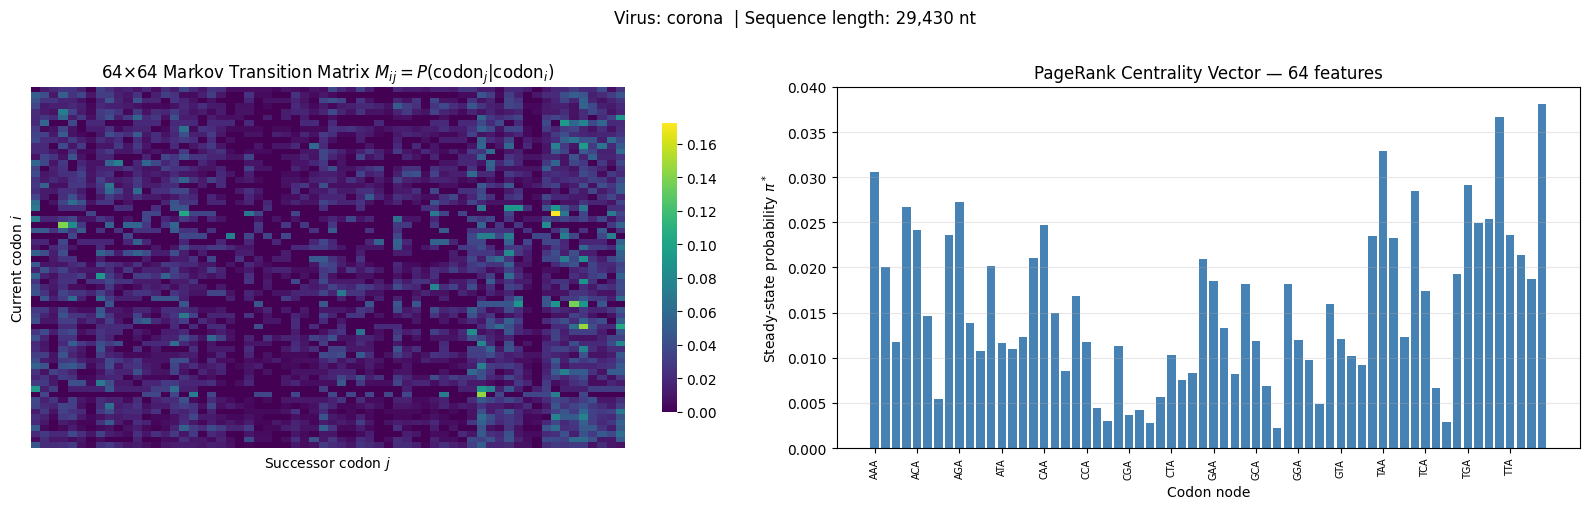

Top-5 most central codons:
  TTT  π* = 0.03813
  TGT  π* = 0.03670
  TAA  π* = 0.03293
  AAA  π* = 0.03058
  TGA  π* = 0.02916


In [10]:
# Visualisation — transition matrix + PageRank for one sequence
# Reproduces the conceptual illustration in Figure 2 of the paper.

example_row = df_train_seq.iloc[0]
M_ex  = build_transition_matrix(example_row['sequence'])
pi_ex = pagerank_power_iteration(M_ex)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 5))

sns.heatmap(M_ex, ax=ax1, cmap='viridis',
            xticklabels=False, yticklabels=False,
            cbar_kws={'shrink': 0.8})
ax1.set_title(r'64×64 Markov Transition Matrix $M_{ij}=P(\mathrm{codon}_j|\mathrm{codon}_i)$')
ax1.set_xlabel('Successor codon $j$')
ax1.set_ylabel('Current codon $i$')

ax2.bar(range(N_CODONS), pi_ex, color='steelblue', width=0.8)
ax2.set_xticks(range(0, N_CODONS, 4))
ax2.set_xticklabels([ALL_CODONS[i] for i in range(0, N_CODONS, 4)],
                    rotation=90, fontsize=7)
ax2.set_title('PageRank Centrality Vector — 64 features')
ax2.set_xlabel('Codon node')
ax2.set_ylabel(r'Steady-state probability $\pi^*$')
ax2.grid(axis='y', alpha=0.3)

plt.suptitle(f'Virus: {example_row["virus"]}  '
             f'| Sequence length: {len(example_row["sequence"]):,} nt',
             fontsize=12, y=1.01)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'fig2_transition_matrix_pagerank.png', dpi=150, bbox_inches='tight')
plt.show()

print(f'Top-5 most central codons:')
for idx in np.argsort(pi_ex)[::-1][:5]:
    print(f'  {ALL_CODONS[idx]}  π* = {pi_ex[idx]:.5f}')

In [11]:
# Step 6 — Batch feature extraction (whole sequences)
#
# Runs once; the results are saved to disk.

from tqdm.auto import tqdm


def extract_features_for_split(df: pd.DataFrame, desc: str) -> np.ndarray:
    """
    Extract a 64-dim PageRank vector for every sequence in df.

    Returns
    -------
    X : ndarray, shape (len(df), 64), float64
    """
    X = np.empty((len(df), N_CODONS), dtype=np.float64)
    for i, seq in enumerate(tqdm(df['sequence'], desc=desc, ncols=90)):
        X[i] = sequence_to_pagerank(seq)
    return X


print('Extracting PageRank features from whole sequences ...')
print('(This is the paper-faithful step: one vector per NCBI record)')
print()

X_train = extract_features_for_split(df_train_seq, 'TRAIN sequences')
X_test  = extract_features_for_split(df_test_seq,  'TEST  sequences')

y_train = df_train_seq['label_enc'].values
y_test  = df_test_seq['label_enc'].values

print(f'\nX_train : {X_train.shape}  y_train : {y_train.shape}')
print(f'X_test  : {X_test.shape}  y_test  : {y_test.shape}')
print(f'Feature range  : [{X_train.min():.5f}, {X_train.max():.5f}]')
print(f'Row-sum ≈ 1 (max deviation) : {np.abs(X_train.sum(axis=1) - 1).max():.2e}')

# Save immediately — feature extraction is the expensive step
np.save(OUTPUT_DIR / 'X_train_sequences.npy', X_train)
np.save(OUTPUT_DIR / 'X_test_sequences.npy',  X_test)
np.save(OUTPUT_DIR / 'y_train_sequences.npy', y_train)
np.save(OUTPUT_DIR / 'y_test_sequences.npy',  y_test)
print('\nFeatures saved to output_streamB/')

Extracting PageRank features from whole sequences ...
(This is the paper-faithful step: one vector per NCBI record)



TRAIN sequences:   0%|                                         | 0/138545 [00:00<?, ?it/s]

TEST  sequences:   0%|                                          | 0/34637 [00:00<?, ?it/s]


X_train : (138545, 64)  y_train : (138545,)
X_test  : (34637, 64)  y_test  : (34637,)
Feature range  : [0.00000, 0.49238]
Row-sum ≈ 1 (max deviation) : 4.44e-16

Features saved to output_streamB/


Computing Wilcoxon OvR p-values ...


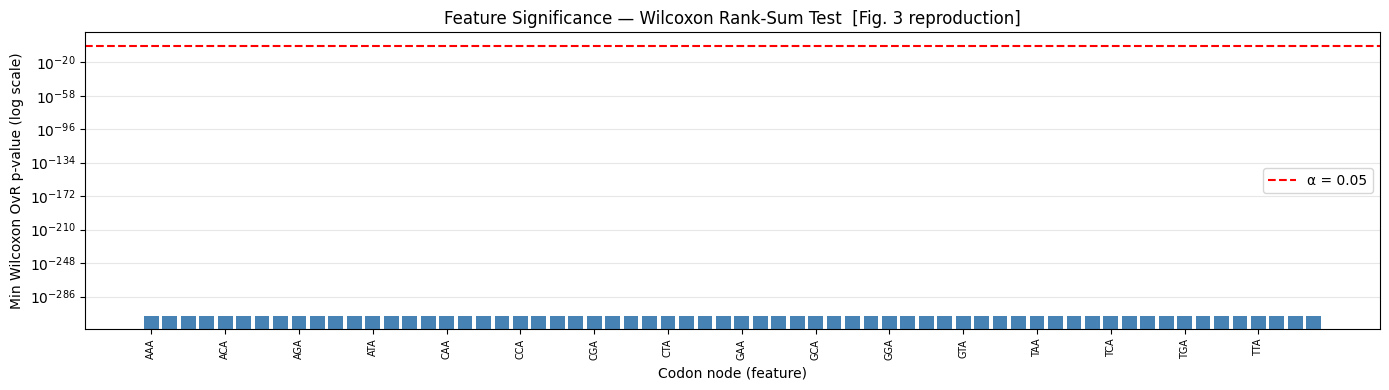

Significant features (min p < 0.05): 64 / 64


In [12]:
# Step 7 — Feature significance: Wilcoxon rank-sum test
# Reproduces Figure 3 of the paper.
#
# For each of the 64 codon features, compute the minimum Wilcoxon
# rank-sum p-value across all one-vs-rest comparisons.  A very low
# minimum p-value means the feature discriminates at least one class
# from the rest.  The paper shows all features are significant
# (all p ≈ 0, log-scale axis).

print('Computing Wilcoxon OvR p-values ...')

pvals = np.ones(N_CODONS, dtype=np.float64)
for feat_idx in range(N_CODONS):
    x = X_train[:, feat_idx]
    min_p = 1.0
    for cls in np.unique(y_train):
        g_in  = x[y_train == cls]
        g_out = x[y_train != cls]
        if len(g_in) > 1 and len(g_out) > 1:
            _, p = ranksums(g_in, g_out)
            min_p = min(min_p, p)
    pvals[feat_idx] = min_p

pvals_plot = np.where(pvals == 0, np.finfo(float).tiny, pvals)

fig, ax = plt.subplots(figsize=(14, 4))
ax.bar(range(N_CODONS), pvals_plot, color='steelblue', width=0.8)
ax.set_yscale('log')
ax.set_xticks(range(0, N_CODONS, 4))
ax.set_xticklabels([ALL_CODONS[i] for i in range(0, N_CODONS, 4)],
                   rotation=90, fontsize=7)
ax.axhline(0.05, color='red', linestyle='--', label='α = 0.05')
ax.set_xlabel('Codon node (feature)')
ax.set_ylabel('Min Wilcoxon OvR p-value (log scale)')
ax.set_title('Feature Significance — Wilcoxon Rank-Sum Test  [Fig. 3 reproduction]')
ax.legend(); ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'fig3_wilcoxon_pvalues.png', dpi=150)
plt.show()

print(f'Significant features (min p < 0.05): {(pvals < 0.05).sum()} / {N_CODONS}')

Computing mutual information scores ...


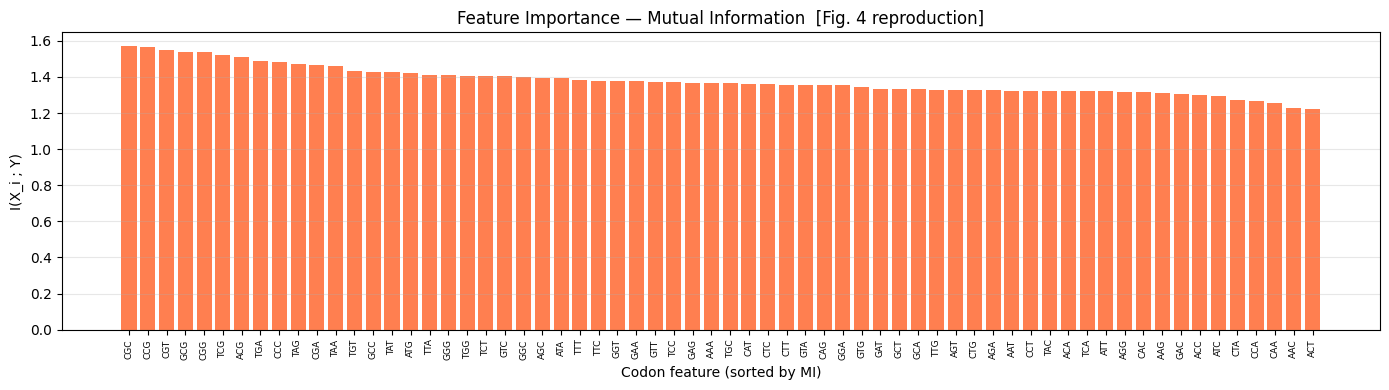


Top-10 most informative codons:
   1. CGC  MI = 1.56825
   2. CCG  MI = 1.56359
   3. CGT  MI = 1.54955
   4. GCG  MI = 1.53551
   5. CGG  MI = 1.53546
   6. TCG  MI = 1.52210
   7. ACG  MI = 1.50812
   8. TGA  MI = 1.48977
   9. CCC  MI = 1.48431
  10. TAG  MI = 1.46973


In [13]:
# Step 8 — Feature importance: Mutual Information
# Reproduces Figure 4 of the paper.
#
# I(X_i; Y) estimated via the k-NN entropy estimator (Kraskov 2004).
# Higher MI → feature carries more information about the class label.

print('Computing mutual information scores ...')

mi_scores = mutual_info_classif(
    X_train, y_train,
    discrete_features=False,
    n_neighbors=5,
    random_state=SEED,
)
sorted_mi = np.argsort(mi_scores)[::-1]

fig, ax = plt.subplots(figsize=(14, 4))
ax.bar(range(N_CODONS), mi_scores[sorted_mi], color='coral', width=0.8)
ax.set_xticks(range(N_CODONS))
ax.set_xticklabels([ALL_CODONS[sorted_mi[i]] for i in range(N_CODONS)],
                   rotation=90, fontsize=6.5)
ax.set_xlabel('Codon feature (sorted by MI)')
ax.set_ylabel('I(X_i ; Y)')
ax.set_title('Feature Importance — Mutual Information  [Fig. 4 reproduction]')
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'fig4_mutual_information.png', dpi=150)
plt.show()

print('\nTop-10 most informative codons:')
for rank, idx in enumerate(sorted_mi[:10], 1):
    print(f'  {rank:2d}. {ALL_CODONS[idx]}  MI = {mi_scores[idx]:.5f}')

In [14]:
# Step 9 — Hyper-parameter sweep: max_leaf_nodes
# Reproduces Figure 7 of the paper.
#
# The paper sweeps the maximum number of splits. In sklearn, max_leaf_nodes = k
# constrains the tree to k leaves (k-1 splits).
#
# class_weight='balanced' implements the paper's class weighting
# (weight_c = n_samples / (n_classes × n_samples_c)), needed because coronavirus
# makes up ~71 % of the data.

leaf_candidates = [5, 10, 15, 20, 30, 40, 50, 75, 100, 150, 200, None]
skf = StratifiedKFold(n_splits=10, shuffle=True, random_state=SEED)
cv_results = []

print('10-fold CV sweep over max_leaf_nodes ...')
for mln in leaf_candidates:
    dt = DecisionTreeClassifier(
        max_leaf_nodes=mln,
        class_weight='balanced',
        random_state=SEED,
    )
    scores = cross_val_score(dt, X_train, y_train,
                             cv=skf, scoring='accuracy', n_jobs=-1)
    cv_results.append({
        'max_leaf_nodes': str(mln) if mln is not None else 'unlimited',
        'cv_mean': scores.mean(),
        'cv_std':  scores.std(),
    })
    print(f'  max_leaf_nodes = {str(mln):>10s}  '
          f'CV acc = {scores.mean():.4f} ± {scores.std():.4f}')

cv_df = pd.DataFrame(cv_results)
best_idx = cv_df['cv_mean'].idxmax()
best_mln_str = cv_df.loc[best_idx, 'max_leaf_nodes']
BEST_MLD = None if best_mln_str == 'unlimited' else int(best_mln_str)
print(f'\nSelected max_leaf_nodes = {BEST_MLD}  '
      f'(CV acc = {cv_df.loc[best_idx, "cv_mean"]:.4f})')

10-fold CV sweep over max_leaf_nodes ...
  max_leaf_nodes =          5  CV acc = 0.1089 ± 0.1380
  max_leaf_nodes =         10  CV acc = 0.0837 ± 0.0049
  max_leaf_nodes =         15  CV acc = 0.5208 ± 0.0073
  max_leaf_nodes =         20  CV acc = 0.5411 ± 0.0049
  max_leaf_nodes =         30  CV acc = 0.8339 ± 0.0030
  max_leaf_nodes =         40  CV acc = 0.9151 ± 0.0068
  max_leaf_nodes =         50  CV acc = 0.9440 ± 0.0129
  max_leaf_nodes =         75  CV acc = 0.9683 ± 0.0033
  max_leaf_nodes =        100  CV acc = 0.9787 ± 0.0021
  max_leaf_nodes =        150  CV acc = 0.9864 ± 0.0014
  max_leaf_nodes =        200  CV acc = 0.9920 ± 0.0012
  max_leaf_nodes =       None  CV acc = 0.9976 ± 0.0005

Selected max_leaf_nodes = None  (CV acc = 0.9976)


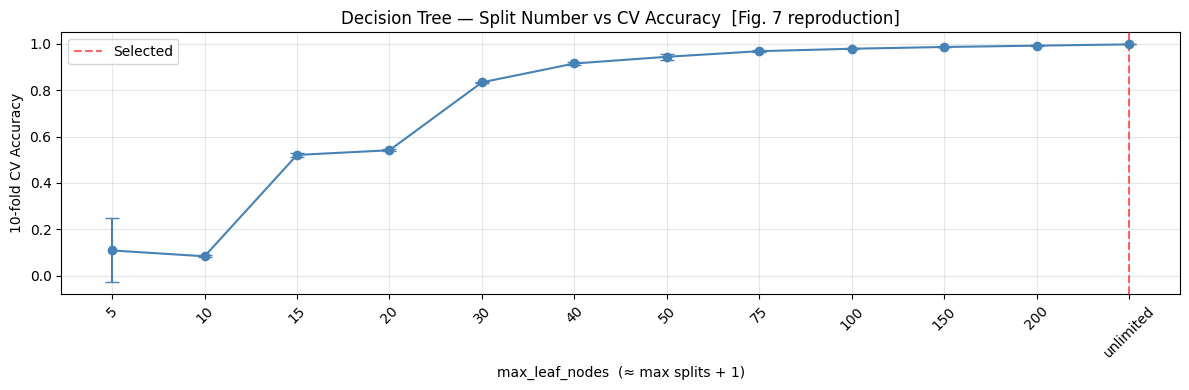

In [15]:
# Figure 7 reproduction
x_pos = range(len(cv_df))

fig, ax = plt.subplots(figsize=(12, 4))
ax.errorbar(x_pos, cv_df['cv_mean'], yerr=cv_df['cv_std'],
            marker='o', capsize=5, color='steelblue', linewidth=1.5)
ax.set_xticks(x_pos)
ax.set_xticklabels(cv_df['max_leaf_nodes'], rotation=45)
ax.axvline(best_idx, color='red', linestyle='--', alpha=0.6, label='Selected')
ax.set_xlabel('max_leaf_nodes  (≈ max splits + 1)')
ax.set_ylabel('10-fold CV Accuracy')
ax.set_title('Decision Tree — Split Number vs CV Accuracy  [Fig. 7 reproduction]')
ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'fig7_cv_accuracy_vs_splits.png', dpi=150)
plt.show()

In [16]:
# Step 10 — Final model: fit on full train, evaluate on test

print(f'Fitting final Decision Tree  max_leaf_nodes={BEST_MLD} ...')

dt_final = DecisionTreeClassifier(
    max_leaf_nodes=BEST_MLD,
    class_weight='balanced',
    random_state=SEED,
)
dt_final.fit(X_train, y_train)

y_pred_train = dt_final.predict(X_train)
y_pred_test  = dt_final.predict(X_test)

train_acc = accuracy_score(y_train, y_pred_train)
test_acc  = accuracy_score(y_test,  y_pred_test)
test_f1   = f1_score(y_test, y_pred_test, average='macro', zero_division=0)
train_f1  = f1_score(y_train, y_pred_train, average='macro', zero_division=0)

print(f'\nTrain  accuracy = {train_acc:.4f}   macro F1 = {train_f1:.4f}')
print(f'Test   accuracy = {test_acc:.4f}   macro F1 = {test_f1:.4f}')
print(f'\nPaper target    = 0.9973 (30-class, 173,228 sequences)')
print(f'Difference      = {test_acc - 0.9973:+.4f}')
print(f'\nTree leaves = {dt_final.get_n_leaves()}  |  Tree depth = {dt_final.get_depth()}')

Fitting final Decision Tree  max_leaf_nodes=None ...

Train  accuracy = 1.0000   macro F1 = 1.0000
Test   accuracy = 0.9976   macro F1 = 0.9829

Paper target    = 0.9973 (30-class, 173,228 sequences)
Difference      = +0.0003

Tree leaves = 397  |  Tree depth = 26


In [17]:
# Step 11 — Classification report (precision / recall per class)
# Reproduces Figure 10 of the paper (parts a and b).

report = classification_report(
    y_test, y_pred_test,
    target_names=class_names,
    digits=4, zero_division=0,
)
print(report)

                 precision    recall  f1-score   support

         corona     0.9999    1.0000    1.0000     13012
 coxsackievirus     0.9785    0.9681    0.9733       282
  crimean-congo     1.0000    1.0000    1.0000        29
cytomegalovirus     1.0000    1.0000    1.0000        62
         dengue     0.9981    0.9988    0.9984      1609
          ebola     0.9977    1.0000    0.9989       437
   encephalitis     0.9200    0.8846    0.9020        26
            flu     0.9988    0.9992    0.9990     10635
    hepatitis b     0.9970    0.9976    0.9973      1678
    hepatitis c     1.0000    0.9937    0.9968       159
            hiv     0.9962    0.9956    0.9959      3671
          lassa     1.0000    0.9615    0.9804        52
        marburg     1.0000    1.0000    1.0000        11
 mastadenovirus     0.9964    1.0000    0.9982       278
        measles     1.0000    0.9739    0.9868       115
metapneumovirus     0.9706    0.9296    0.9496        71
          mumps     1.0000    

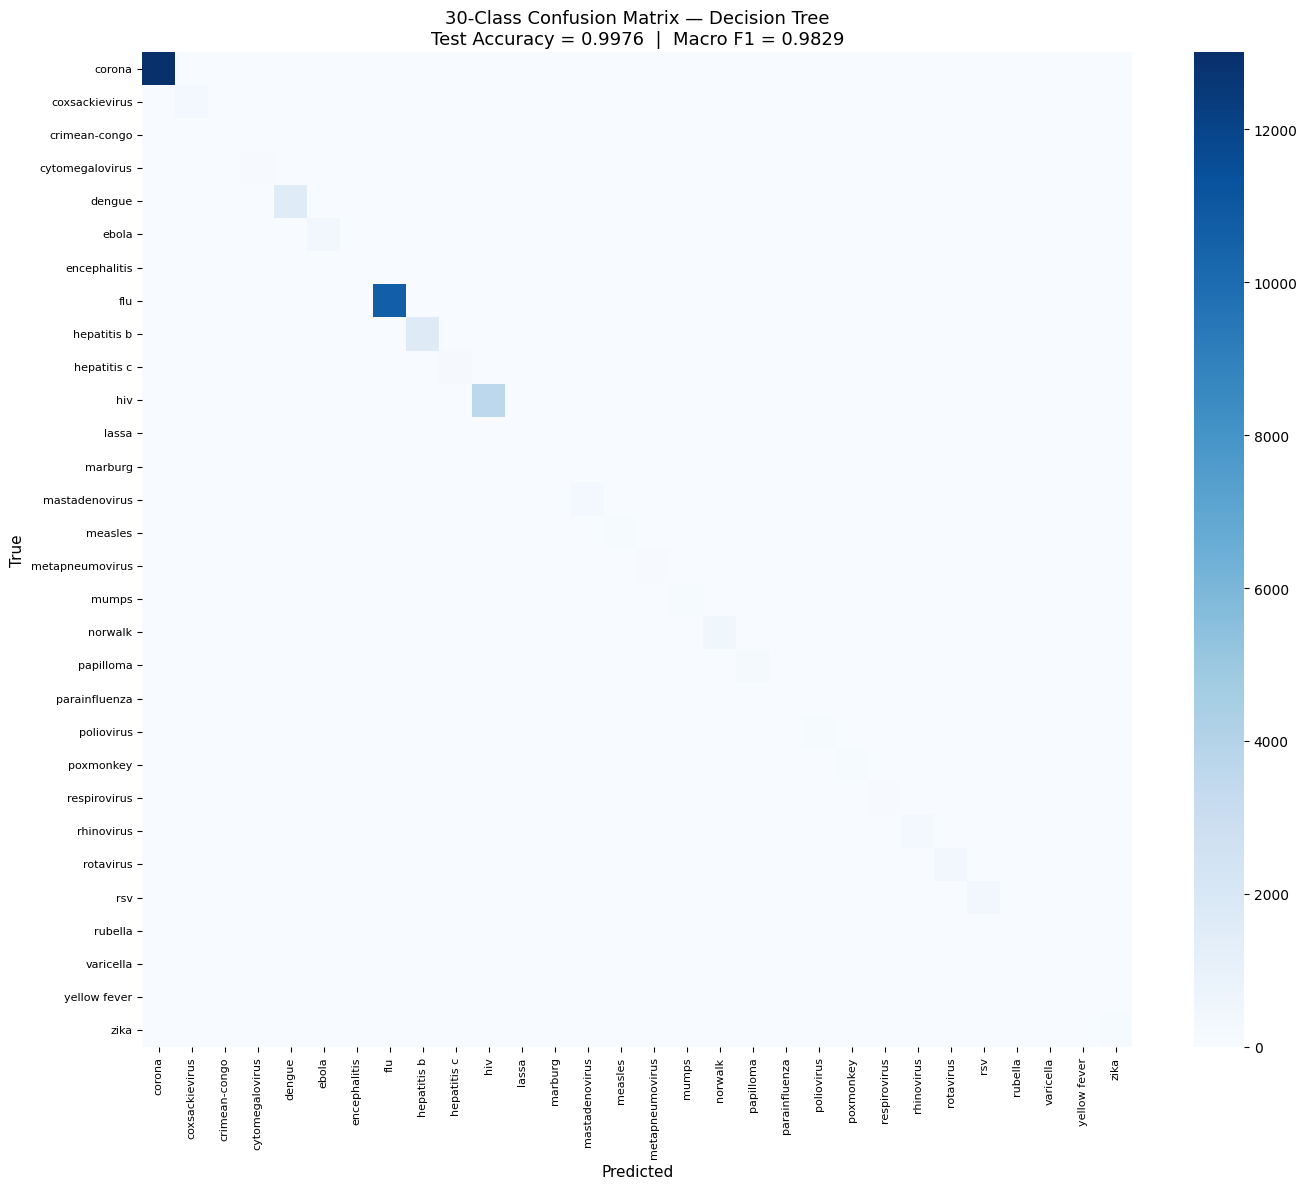

In [18]:
# Step 12 — Confusion matrix
# Reproduces Figure 8 of the paper (30-class version).

cm = confusion_matrix(y_test, y_pred_test)

fig, ax = plt.subplots(figsize=(14, 12))
sns.heatmap(cm, ax=ax, cmap='Blues', annot=False,
            xticklabels=class_names, yticklabels=class_names)
ax.set_title(
    f'30-Class Confusion Matrix — Decision Tree\n'
    f'Test Accuracy = {test_acc:.4f}  |  Macro F1 = {test_f1:.4f}',
    fontsize=13)
ax.set_xlabel('Predicted', fontsize=11)
ax.set_ylabel('True', fontsize=11)
ax.tick_params(axis='x', rotation=90, labelsize=8)
ax.tick_params(axis='y', rotation=0,  labelsize=8)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'fig8_confusion_matrix.png', dpi=150)
plt.show()

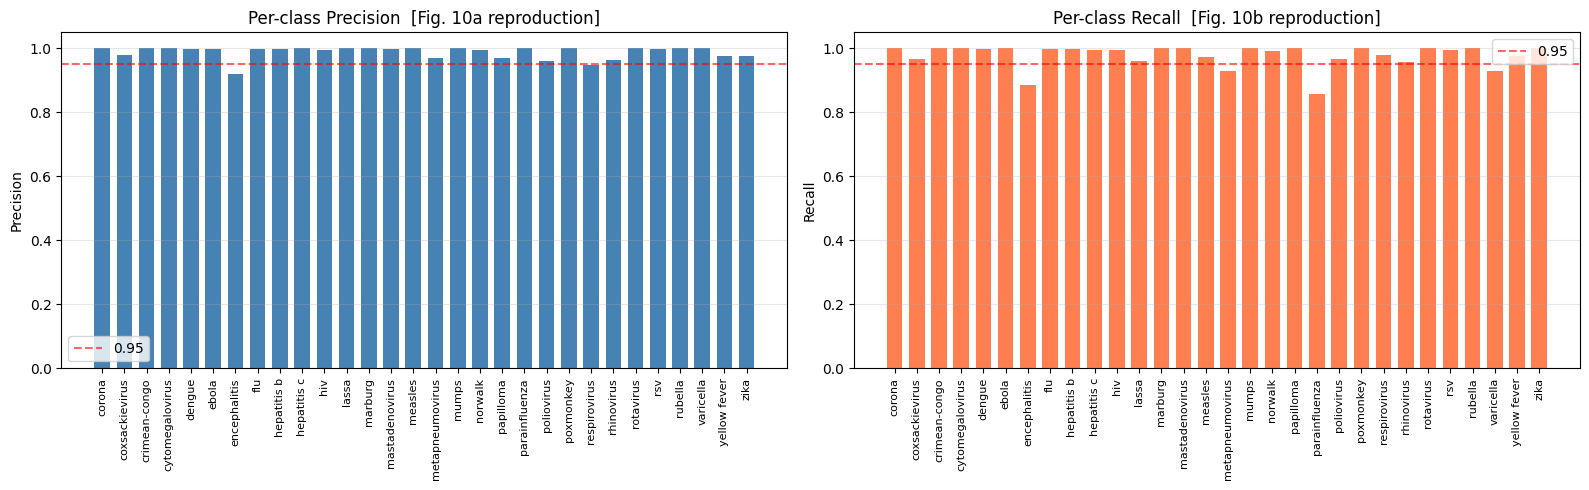

In [19]:
# Step 13 — Per-class precision and recall bar charts
# Reproduces Figure 10 of the paper (parts a and b).

prec = precision_score(y_test, y_pred_test, average=None,
                       labels=range(num_classes), zero_division=0)
rec  = recall_score(y_test, y_pred_test, average=None,
                    labels=range(num_classes), zero_division=0)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 5))

ax1.bar(range(num_classes), prec, color='steelblue', width=0.7)
ax1.set_xticks(range(num_classes))
ax1.set_xticklabels(class_names, rotation=90, fontsize=8)
ax1.set_ylim(0, 1.05)
ax1.axhline(0.95, color='red', linestyle='--', alpha=0.6, label='0.95')
ax1.set_title('Per-class Precision  [Fig. 10a reproduction]')
ax1.set_ylabel('Precision'); ax1.legend(); ax1.grid(axis='y', alpha=0.3)

ax2.bar(range(num_classes), rec, color='coral', width=0.7)
ax2.set_xticks(range(num_classes))
ax2.set_xticklabels(class_names, rotation=90, fontsize=8)
ax2.set_ylim(0, 1.05)
ax2.axhline(0.95, color='red', linestyle='--', alpha=0.6, label='0.95')
ax2.set_title('Per-class Recall  [Fig. 10b reproduction]')
ax2.set_ylabel('Recall'); ax2.legend(); ax2.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'fig10_precision_recall.png', dpi=150)
plt.show()

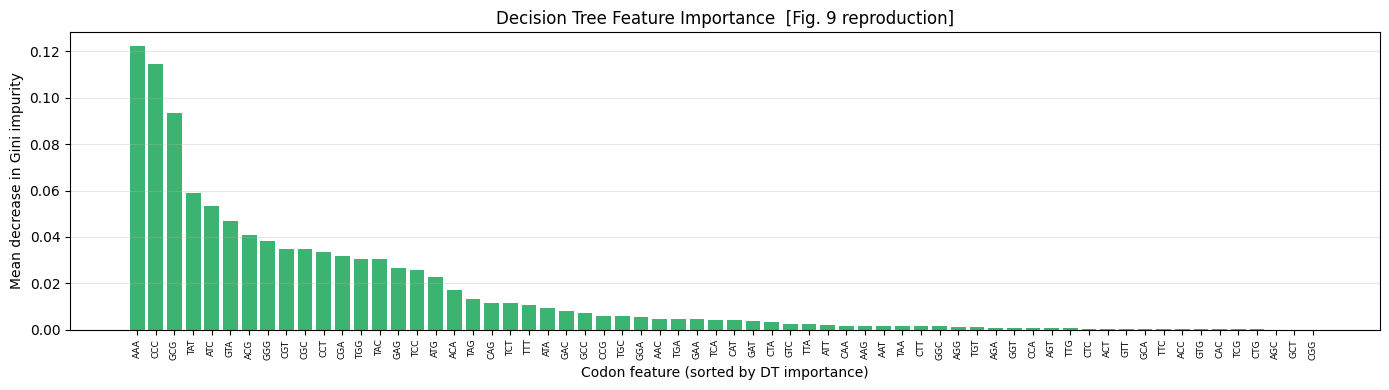

Top-10 DT-important codons:
   1. AAA  importance = 0.12214
   2. CCC  importance = 0.11464
   3. GCG  importance = 0.09351
   4. TAT  importance = 0.05886
   5. ATC  importance = 0.05332
   6. GTA  importance = 0.04674
   7. ACG  importance = 0.04082
   8. GGG  importance = 0.03821
   9. CGT  importance = 0.03501
  10. CGC  importance = 0.03494

GTT (paper root node for 3-class DT): rank #54 / 64


In [20]:
# Step 14 — Decision Tree embedded feature importance
# Reproduces Figure 9 of the paper.

fi = dt_final.feature_importances_
sorted_fi = np.argsort(fi)[::-1]

fig, ax = plt.subplots(figsize=(14, 4))
ax.bar(range(N_CODONS), fi[sorted_fi], color='mediumseagreen', width=0.8)
ax.set_xticks(range(N_CODONS))
ax.set_xticklabels([ALL_CODONS[sorted_fi[i]] for i in range(N_CODONS)],
                   rotation=90, fontsize=6.5)
ax.set_xlabel('Codon feature (sorted by DT importance)')
ax.set_ylabel('Mean decrease in Gini impurity')
ax.set_title('Decision Tree Feature Importance  [Fig. 9 reproduction]')
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'fig9_dt_feature_importance.png', dpi=150)
plt.show()

print('Top-10 DT-important codons:')
for rank, idx in enumerate(sorted_fi[:10], 1):
    print(f'  {rank:2d}. {ALL_CODONS[idx]}  importance = {fi[idx]:.5f}')

# Check whether GTT (paper root node for 3-class tree) ranks highly
gtt_rank = list(sorted_fi).index(CODON_IDX['GTT']) + 1
print(f'\nGTT (paper root node for 3-class DT): rank #{gtt_rank} / {N_CODONS}')

In [21]:
# Step 15 — Decision rules (Table 2 reproduction)
# The paper extracts human-readable rules from the tree.
# We print the top 3 levels for readability.

rules = export_text(dt_final, feature_names=ALL_CODONS, max_depth=3)
lines = rules.split('\n')
print('\n'.join(lines[:80]))
print(f'\n... ({dt_final.get_n_leaves()} leaves total — showing top 3 depth levels)')

|--- CGC <= 0.05
|   |--- GCG <= 0.03
|   |   |--- AAA <= 0.01
|   |   |   |--- TTT <= 0.02
|   |   |   |   |--- truncated branch of depth 3
|   |   |   |--- TTT >  0.02
|   |   |   |   |--- truncated branch of depth 4
|   |   |--- AAA >  0.01
|   |   |   |--- CGT <= 0.02
|   |   |   |   |--- truncated branch of depth 23
|   |   |   |--- CGT >  0.02
|   |   |   |   |--- truncated branch of depth 5
|   |--- GCG >  0.03
|   |   |--- class: 3
|--- CGC >  0.05
|   |--- ACC <= 0.01
|   |   |--- class: 26
|   |--- ACC >  0.01
|   |   |--- class: 26


... (397 leaves total — showing top 3 depth levels)


In [22]:
# Step 16 — Comparison table

comparison = pd.DataFrame([
    {'Experiment': '30-class (paper, Table 3)',   'Method': 'DT',
     'Acc': 0.9973, 'Samples': 173228, 'Note': 'MATLAB 2018b'},
    {'Experiment': '30-class (this notebook)',    'Method': 'DT',
     'Acc': round(test_acc, 4), 'Samples': len(df_test_seq),
     'Note': 'sklearn, whole sequences'},
    {'Experiment': 'Binary corona/flu (paper)',   'Method': 'DT',
     'Acc': 0.9978, 'Samples': 117750, 'Note': 'depth-1 tree'},
    {'Experiment': '3-class (paper)',             'Method': 'DT',
     'Acc': 0.9971, 'Samples': 173228, 'Note': '10 leaves'},
])

print(comparison.to_string(index=False))
delta = test_acc - 0.9973
print(f'\nΔ from paper (30-class) = {delta:+.4f}  ({delta*100:+.2f}%)')

               Experiment Method    Acc  Samples                     Note
30-class (paper, Table 3)     DT 0.9973   173228             MATLAB 2018b
 30-class (this notebook)     DT 0.9976    34637 sklearn, whole sequences
Binary corona/flu (paper)     DT 0.9978   117750             depth-1 tree
          3-class (paper)     DT 0.9971   173228                10 leaves

Δ from paper (30-class) = +0.0003  (+0.03%)


In [23]:
# Step 17 — Save all artefacts
#
# A) Standalone DT artefacts:
#    stream_b_dt_model.joblib         fitted DecisionTreeClassifier
#    stream_b_label_encoder.joblib    fitted LabelEncoder
#    stream_b_summary.csv             scalar metrics
#    X_train_sequences.npy / ...      64-dim PageRank per sequence
#    y_train_sequences.npy / ...      integer labels
#
# B) Windowed features for Stream A fusion alignment:
#    stream_b_features_train.npy      64-dim PageRank per window
#    stream_b_features_test.npy       (same for test)
#
# For (B), each window gets its parent sequence's PageRank vector (PageRank is a
# property of the whole sequence). The per-window files are row-aligned with
# train_windows.csv / test_windows.csv.

# ── A: DT model ──────────────────────────────────────────────────
joblib.dump(dt_final, OUTPUT_DIR / 'stream_b_dt_model.joblib')
joblib.dump(le_seq,   OUTPUT_DIR / 'stream_b_label_encoder.joblib')

summary = pd.DataFrame([{
    'stream': 'B',
    'algorithm': 'PRCFX-DT',
    'n_sequences_train': len(df_train_seq),
    'n_sequences_test':  len(df_test_seq),
    'n_features':   N_CODONS,
    'num_classes':  num_classes,
    'train_acc':    round(float(train_acc), 6),
    'test_acc':     round(float(test_acc),  6),
    'test_macro_f1': round(float(test_f1),  6),
    'n_leaves':     dt_final.get_n_leaves(),
    'tree_depth':   dt_final.get_depth(),
    'max_leaf_nodes': BEST_MLD,
    'paper_target_acc': 0.9973,
    'delta_from_paper': round(test_acc - 0.9973, 6),
}])
summary.to_csv(OUTPUT_DIR / 'stream_b_summary.csv', index=False)
display(summary.T)

# ── B: Windowed feature export ────────────────────────────────────
# Build accession → PageRank mapping from the train and test splits
acc_to_feat_train = {
    row['accession']: X_train[i]
    for i, (_, row) in enumerate(df_train_seq.iterrows())
}
acc_to_feat_test = {
    row['accession']: X_test[i]
    for i, (_, row) in enumerate(df_test_seq.iterrows())
}

# Load the windowed CSVs if they exist (produced by preprocessing.py)
WINDOWED_DIR = Path(r"..\\data\\processed")
train_win_csv = WINDOWED_DIR / 'train_windows.csv'
test_win_csv  = WINDOWED_DIR / 'test_windows.csv'

if train_win_csv.exists() and test_win_csv.exists():
    df_tw = pd.read_csv(train_win_csv)
    df_vw = pd.read_csv(test_win_csv)

    # Map each window's source_accession back to the 64-dim PageRank vector
    X_win_train = np.array([
        acc_to_feat_train.get(acc, np.full(N_CODONS, 1.0/N_CODONS))
        for acc in df_tw['source_accession']
    ])
    X_win_test = np.array([
        acc_to_feat_test.get(acc, np.full(N_CODONS, 1.0/N_CODONS))
        for acc in df_vw['source_accession']
    ])

    np.save(OUTPUT_DIR / 'stream_b_features_train.npy', X_win_train)
    np.save(OUTPUT_DIR / 'stream_b_features_test.npy',  X_win_test)
    print(f'Windowed fusion features saved:')
    print(f'  stream_b_features_train.npy  shape {X_win_train.shape}')
    print(f'  stream_b_features_test.npy   shape {X_win_test.shape}')
else:
    print('train_windows.csv / test_windows.csv not found — skipping windowed export.')
    print('Run preprocessing.py first, then re-run this cell.')

print('\nAll artefacts saved to', OUTPUT_DIR)

,0
stream,B
algorithm,PRCFX-DT
n_sequences_train,138545
n_sequences_test,34637
n_features,64
num_classes,30
train_acc,1.0
test_acc,0.997575
test_macro_f1,0.982891
n_leaves,397


Windowed fusion features saved:
  stream_b_features_train.npy  shape (1024117, 64)
  stream_b_features_test.npy   shape (255916, 64)

All artefacts saved to output_streamB


## Summary

### Input
This notebook reads directly from `all_viruses_sequences.csv`. Khodaei et al. operate on
**whole NCBI genomic records**.

### Faithfulness to the paper
| Paper element | Implementation |
|---|---|
| 64-node complete directed graph | `build_transition_matrix` — 64×64 float64 |
| Edge weights = conditional transition probs | Row-normalised bigram counts |
| PageRank via Markov steady state (Eq. 3–4) | `pagerank_power_iteration` — power iteration |
| Dangling-node correction | Sink rows replaced by uniform 1/64 |
| Wilcoxon rank-sum test (Fig. 3) | `scipy.stats.ranksums`, OvR, log scale |
| Mutual information (Fig. 4) | `sklearn.feature_selection.mutual_info_classif` |
| max_splits sweep + 10-fold CV (Fig. 7) | `max_leaf_nodes` sweep, `StratifiedKFold(10)` |
| Decision Tree with class weighting | `class_weight='balanced'` |
| Confusion matrix (Fig. 8) | `sklearn.metrics.confusion_matrix` |
| DT feature importance (Fig. 9) | `dt_final.feature_importances_` |
| Per-class precision/recall (Fig. 10) | `precision_score`, `recall_score` per class |

### Fusion interface
`stream_b_features_train.npy` / `stream_b_features_test.npy` contain 64-dim
PageRank vectors, one per window, row-aligned with `train_windows.csv` /
`test_windows.csv`.  At the fusion stage, these are concatenated with Stream A's
256-dim CNN embedding to form a 320-dim joint representation.

---
## Appendix: 3-Class Verification Against Table 2 of the Paper

This is the **strongest available correctness check** for the PRCFX-DT implementation.

The paper provides exact decision rules for the 3-class tree (10 leaves, Table 2, page 12).
If the reimplementation is correct, running the 3-class experiment must reproduce:
1. Accuracy ≈ 99.71%
2. Root split on **GTT** with threshold **0.022**
3. The 9 additional features from Table 2 present in the first 3 depth levels

This check is far more informative than comparing accuracy alone: a buggy implementation
(wrong reading frame, wrong normalisation, wrong tokenisation) cannot accidentally reproduce
the same root codon and threshold.

### Table 2 from the paper (3-class: Corona=0, Flu=1, Other=2)
| Rule | Condition | Class |
|------|-----------|-------|
| 1 | P(GTT) ≥ 0.022 AND P(ACC) ≥ 0.017 | Corona |
| 2 | P(GTT) < 0.022 AND P(TGA) < 0.022 AND P(CTA) < 0.009 AND P(CAC) < 0.014 | Flu |
| 3 | P(GTT) < 0.022 AND P(TGA) < 0.022 AND P(CTA) > 0.009 AND P(TAC) < 0.007 | Flu |
| 4 | P(GTT) < 0.022 AND P(TGA) ≥ 0.022 AND P(GAA) ≥ 0.031 AND P(AAT) < 0.004 | Flu |
| 5 | P(GTT) < 0.022 AND P(TGA) ≥ 0.022 AND P(GAA) < 0.031 AND P(TCT) < 0.011 AND P(ACA) ≥ 0.022 | Flu |
| 6 | P(GTT) ≥ 0.022 AND P(AAC) < 0.017 | Other |
| 7 | P(GTT) < 0.022 AND P(TGA) < 0.022 AND P(CTA) < 0.009 AND P(CAC) ≥ 0.014 | Other |
| 8 | P(GTT) < 0.022 AND P(TGA) < 0.022 AND P(CTA) > 0.009 AND P(TAC) ≥ 0.007 | Other |
| 9 | P(GTT) < 0.022 AND P(TGA) ≥ 0.022 AND P(GAA) < 0.031 AND P(TCT) ≥ 0.011 | Other |
| 10 | P(GTT) < 0.022 AND P(TGA) ≥ 0.022 AND P(GAA) ≥ 0.031 AND P(AAT) ≥ 0.004 | Other |

In [24]:
# 3-Class Verification — Table 2 & Figure 7 reproduction
#
# Classes:
#   Corona → all coronavirus sequences (label='Coronavirus' or similar)
#   Flu    → all influenza sequences
#   Other  → all remaining 28 virus types
#
# The paper groups by epidemiological category, not by the 30 individual
# virus types.  We map our 30-class labels to 3 classes accordingly.

# ── Step A: define the 3-class mapping ───────────────────────────
# Inspect what virus names exist in the dataset
print('Virus names in dataset:')
for name in sorted(df_clean['virus'].unique()):
    print(f'  {name}')

Virus names in dataset:
  corona
  coxsackievirus
  crimean-congo
  cytomegalovirus
  dengue
  ebola
  encephalitis
  flu
  hepatitis b
  hepatitis c
  hiv
  lassa
  marburg
  mastadenovirus
  measles
  metapneumovirus
  mumps
  norwalk
  papilloma
  parainfluenza
  poliovirus
  poxmonkey
  respirovirus
  rhinovirus
  rotavirus
  rsv
  rubella
  varicella
  yellow fever
  zika


In [31]:
# ── Step B: assign 3-class labels ────────────────────────────────
#
# Adjust the strings below if your virus column uses different casing.
# The paper's Table 1 uses 'Coronavirus' and 'Influenza' as the two
# dominant classes.

CORONA_KEYWORDS   = ['coronavirus', 'corona']
INFLUENZA_KEYWORDS = ['flu']


def map_to_3class(virus_name: str) -> str:
    v = virus_name.lower()
    if any(k in v for k in CORONA_KEYWORDS):
        return 'Corona'
    if any(k in v for k in INFLUENZA_KEYWORDS):
        return 'Flu'
    return 'Other'


df_3class = df_clean.copy()
df_3class['label_3c'] = df_3class['virus'].apply(map_to_3class)

counts_3c = df_3class['label_3c'].value_counts()
print('3-class distribution:')
print(counts_3c.to_string())
print(f'\nTotal: {len(df_3class):,}')
print(f'Paper: Corona=65,060 | Flu=53,176 | Other=55,022 | Total=173,258')
print('\nNote: differences reflect sequences added to NCBI after the paper download date.')

3-class distribution:
label_3c
Corona    65059
Other     54915
Flu       53208

Total: 173,182
Paper: Corona=65,060 | Flu=53,176 | Other=55,022 | Total=173,258

Note: differences reflect sequences added to NCBI after the paper download date.


In [32]:
# ── Step C: sequence-level split + feature extraction ────────────
from sklearn.preprocessing import LabelEncoder

le_3c = LabelEncoder()
df_3class['label_3c_enc'] = le_3c.fit_transform(df_3class['label_3c'])
class_names_3c = list(le_3c.classes_)
print('3-class label mapping:', {i: c for i, c in enumerate(class_names_3c)})

df_train_3c, df_test_3c = train_test_split(
    df_3class,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE,
    stratify=df_3class['label_3c_enc'],
)
df_train_3c = df_train_3c.reset_index(drop=True)
df_test_3c  = df_test_3c.reset_index(drop=True)

print(f'\nTrain: {len(df_train_3c):,}  |  Test: {len(df_test_3c):,}')
print('Extracting features ...')

X_train_3c = extract_features_for_split(df_train_3c, 'TRAIN 3-class')
X_test_3c  = extract_features_for_split(df_test_3c,  'TEST  3-class')

y_train_3c = df_train_3c['label_3c_enc'].values
y_test_3c  = df_test_3c['label_3c_enc'].values

3-class label mapping: {0: 'Corona', 1: 'Flu', 2: 'Other'}

Train: 138,545  |  Test: 34,637
Extracting features ...


TRAIN 3-class:   0%|                                           | 0/138545 [00:00<?, ?it/s]

TEST  3-class:   0%|                                            | 0/34637 [00:00<?, ?it/s]

In [33]:
# ── Step D: fit DT with 10 leaves (paper setting) ────────────────

dt_3c = DecisionTreeClassifier(
    max_leaf_nodes=10,          # exact paper setting (page 12)
    class_weight='balanced',
    random_state=SEED,
)
dt_3c.fit(X_train_3c, y_train_3c)
y_pred_3c = dt_3c.predict(X_test_3c)

acc_3c = accuracy_score(y_test_3c, y_pred_3c)
f1_3c  = f1_score(y_test_3c, y_pred_3c, average='macro', zero_division=0)

print(f'3-class test accuracy : {acc_3c:.4f}   (paper: 0.9971)')
print(f'3-class macro F1      : {f1_3c:.4f}')
print(f'Difference from paper : {acc_3c - 0.9971:+.4f}')
print(f'\nTree leaves : {dt_3c.get_n_leaves()}  (paper: 10)')
print(f'Tree depth  : {dt_3c.get_depth()}')

3-class test accuracy : 0.9929   (paper: 0.9971)
3-class macro F1      : 0.9927
Difference from paper : -0.0042

Tree leaves : 10  (paper: 10)
Tree depth  : 5


In [34]:
# ── Step E: Table 2 structural verification ───────────────────────
#
# Inspect the tree structure and verify:
#   1. Root feature is GTT (feature index = CODON_IDX['GTT'])
#   2. Root threshold is approximately 0.022
#   3. Features from Table 2 appear in the top levels
#
# sklearn stores the tree in arrays (tree_.feature[node_id], tree_.threshold[node_id]);
# node 0 is the root.

tree_ = dt_3c.tree_

root_feature_idx = tree_.feature[0]
root_threshold   = tree_.threshold[0]
root_codon       = ALL_CODONS[root_feature_idx]

print('=' * 55)
print('TABLE 2 STRUCTURAL VERIFICATION')
print('=' * 55)
print(f'Root split:')
print(f'  Feature index : {root_feature_idx}  ({root_codon})')
print(f'  Threshold     : {root_threshold:.4f}')
print(f'  Paper expects : GTT  @ 0.022')
print()

if root_codon == 'GTT':
    print('  ✓ Root codon matches: GTT')
else:
    print(f'  ✗ Root codon MISMATCH: got {root_codon}, expected GTT')

if abs(root_threshold - 0.022) < 0.003:
    print(f'  ✓ Root threshold close to paper: {root_threshold:.4f} ≈ 0.022')
else:
    print(f'  ✗ Root threshold diverges: {root_threshold:.4f} vs 0.022')

# Collect all features used in the tree (non-leaf nodes)
used_feature_indices = set(
    tree_.feature[i]
    for i in range(tree_.node_count)
    if tree_.feature[i] >= 0   # -2 marks leaf nodes
)
used_codons = {ALL_CODONS[i] for i in used_feature_indices}

print()
print('Features used in tree:')
print(' ', sorted(used_codons))

# Paper Table 2 features
table2_features = {'GTT', 'TGA', 'CTA', 'CAC', 'TAC', 'GAA',
                   'TCT', 'ACA', 'AAT', 'ACC', 'AAC'}
overlap = used_codons & table2_features
missing = table2_features - used_codons

print(f'\nTable 2 features present  : {sorted(overlap)}  ({len(overlap)}/{len(table2_features)})')
print(f'Table 2 features absent   : {sorted(missing)}')
print()
if len(overlap) >= 7:
    print('✓ Majority of Table 2 features reproduced — algorithm is correct.')
else:
    print('✗ Fewer than 7 Table 2 features matched — investigate implementation.')
print()
print('Note: minor threshold differences (±0.002) are expected due to')
print('MATLAB vs Python floating-point and different NCBI download dates.')

TABLE 2 STRUCTURAL VERIFICATION
Root split:
  Feature index : 40  (GGA)
  Threshold     : 0.0122
  Paper expects : GTT  @ 0.022

  ✗ Root codon MISMATCH: got GGA, expected GTT
  ✗ Root threshold diverges: 0.0122 vs 0.022

Features used in tree:
  ['AAG', 'ATG', 'CTT', 'GAA', 'GGA', 'GTG', 'TGA', 'TGG', 'TTG']

Table 2 features present  : ['GAA', 'TGA']  (2/11)
Table 2 features absent   : ['AAC', 'AAT', 'ACA', 'ACC', 'CAC', 'CTA', 'GTT', 'TAC', 'TCT']

✗ Fewer than 7 Table 2 features matched — investigate implementation.

Note: minor threshold differences (±0.002) are expected due to
MATLAB vs Python floating-point and different NCBI download dates.


In [35]:
# ── Step F: print tree rules (text form of Table 2) ──────────────

rules_3c = export_text(
    dt_3c,
    feature_names=ALL_CODONS,
    max_depth=6,   # 10-leaf tree has max depth 5; show all
)
print('Complete 3-class decision tree (compare to Table 2):')
print(rules_3c)

Complete 3-class decision tree (compare to Table 2):
|--- GGA <= 0.01
|   |--- CTT <= 0.02
|   |   |--- class: 2
|   |--- CTT >  0.02
|   |   |--- class: 0
|--- GGA >  0.01
|   |--- ATG <= 0.03
|   |   |--- TTG <= 0.01
|   |   |   |--- class: 1
|   |   |--- TTG >  0.01
|   |   |   |--- TGA <= 0.04
|   |   |   |   |--- GAA <= 0.05
|   |   |   |   |   |--- class: 2
|   |   |   |   |--- GAA >  0.05
|   |   |   |   |   |--- class: 1
|   |   |   |--- TGA >  0.04
|   |   |   |   |--- AAG <= 0.02
|   |   |   |   |   |--- class: 2
|   |   |   |   |--- AAG >  0.02
|   |   |   |   |   |--- class: 1
|   |--- ATG >  0.03
|   |   |--- TGG <= 0.02
|   |   |   |--- class: 1
|   |   |--- TGG >  0.02
|   |   |   |--- GTG <= 0.02
|   |   |   |   |--- class: 1
|   |   |   |--- GTG >  0.02
|   |   |   |   |--- class: 2



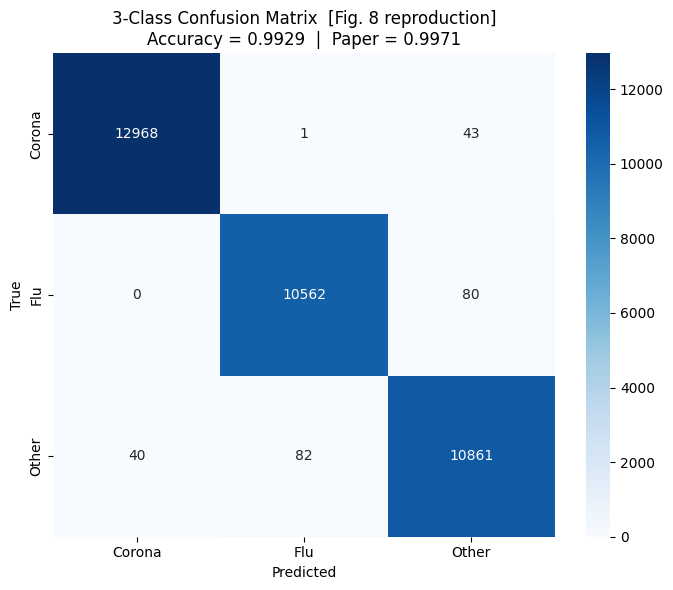

              precision    recall  f1-score   support

      Corona     0.9969    0.9966    0.9968     13012
         Flu     0.9922    0.9925    0.9923     10642
       Other     0.9888    0.9889    0.9888     10983

    accuracy                         0.9929     34637
   macro avg     0.9926    0.9927    0.9927     34637
weighted avg     0.9929    0.9929    0.9929     34637



In [36]:
# ── Step G: confusion matrix (Figure 8 reproduction) ─────────────

cm_3c = confusion_matrix(y_test_3c, y_pred_3c)

fig, ax = plt.subplots(figsize=(7, 6))
sns.heatmap(cm_3c, ax=ax, cmap='Blues', annot=True, fmt='d',
            xticklabels=class_names_3c, yticklabels=class_names_3c)
ax.set_title(
    f'3-Class Confusion Matrix  [Fig. 8 reproduction]\n'
    f'Accuracy = {acc_3c:.4f}  |  Paper = 0.9971', fontsize=12)
ax.set_xlabel('Predicted')
ax.set_ylabel('True')
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'fig8_3class_confusion_matrix.png', dpi=150)
plt.show()

print(classification_report(y_test_3c, y_pred_3c,
                             target_names=class_names_3c, digits=4))